Synced Environment -> numpy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1
Training rows: 58,400 | Testing rows: 14,600


,Model,MAE,RMSE,R2_Score
0,Baseline Random Forest,18.17,24.42,0.6945
1,Tuned HistGradientBoosting,10.52,14.44,0.8932



--- Tuned Model MAE by Category ---
Category
Groceries      12.239022
Clothing       10.680768
Toys           10.164595
Electronics     9.865666
Furniture       7.277063
Name: Abs_Error, dtype: float64

--- Tuned Model MAE by Promotion & Epidemic ---
Promotion  Epidemic
0          0            9.546492
           1            8.787864
1          0           13.272787
           1           11.286364
Name: Abs_Error, dtype: float64


AttributeError: 'numpy.ndarray' object has no attribute 'plot'

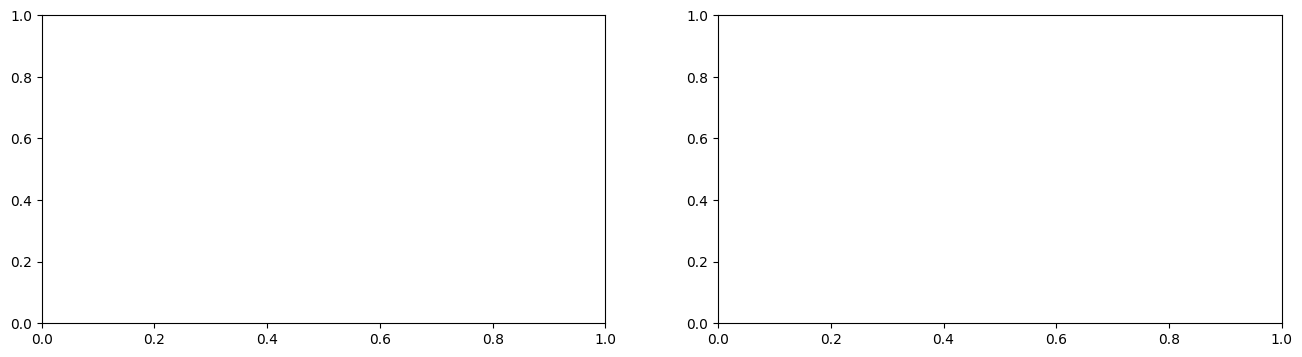

In [2]:
import numpy as np
import pandas as pd
import sklearn
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

print(f"Synced Environment -> numpy: {np.__version__} | pandas: {pd.__version__} | sklearn: {sklearn.__version__}")

url = "https://raw.githubusercontent.com/awais-DS/Data/refs/heads/main/sales_data.csv"
df = pd.read_csv(url)

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Store ID', 'Product ID', 'Date']).reset_index(drop=True)

df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Is_Weekend'] = (df['Day_of_Week'] >= 5).astype(int)
df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12)

df['Effective_Price'] = df['Price'] * (1 - df['Discount'] / 100)
df['Price_vs_Competitor'] = df['Effective_Price'] - df['Competitor Pricing']
df['Price_Ratio'] = df['Effective_Price'] / (df['Competitor Pricing'] + 1e-5)

prev_promo = df.groupby(['Store ID', 'Product ID'])['Promotion'].shift(1).fillna(0)
df['Promo_Started'] = ((df['Promotion'] == 1) & (prev_promo == 0)).astype(int)
df['Promo_Discount_Power'] = df['Promotion'] * df['Discount']

grp = df.groupby(['Store ID', 'Product ID'])['Demand']
df['Demand_Lag_1'] = grp.shift(1)
df['Demand_Lag_2'] = grp.shift(2)
df['Demand_Lag_7'] = grp.shift(7)
df['Demand_Lag_14'] = grp.shift(14)

df['Demand_Rolling_7D'] = grp.transform(lambda x: x.shift(1).rolling(7).mean())
df['Demand_Rolling_14D'] = grp.transform(lambda x: x.shift(1).rolling(14).mean())
df['Demand_Rolling_30D'] = grp.transform(lambda x: x.shift(1).rolling(30).mean())
df['Demand_Std_7D'] = grp.transform(lambda x: x.shift(1).rolling(7).std())
df['Days_of_Inventory'] = df['Inventory Level'] / (df['Demand_Rolling_7D'] + 1)

df_model = df.dropna().copy()

split_date = df_model['Date'].quantile(0.80)
train_mask = df_model['Date'] < split_date
test_mask = df_model['Date'] >= split_date

train_df = df_model[train_mask].copy()
test_df = df_model[test_mask].copy()

cat_avg_price_map = train_df.groupby('Category')['Effective_Price'].mean().to_dict()
promo_cat_map = train_df.groupby(['Category', 'Promotion'])['Demand'].mean().to_dict()
cat_dow_map = train_df.groupby(['Category', 'Day_of_Week'])['Demand'].mean().to_dict()

for part in [train_df, test_df]:
    part['Category_Avg_Price'] = part['Category'].map(cat_avg_price_map)
    part['Price_vs_Category'] = part['Effective_Price'] - part['Category_Avg_Price']
    part['Promo_Category_Mean'] = part.set_index(['Category', 'Promotion']).index.map(promo_cat_map)
    part['Category_DayOfWeek_Mean'] = part.set_index(['Category', 'Day_of_Week']).index.map(cat_dow_map)

drop_cols = ['Date', 'Demand', 'Units Sold']
cat_cols = ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']

X_train = train_df.drop(columns=drop_cols).copy()
y_train = train_df['Demand'].copy()
X_test = test_df.drop(columns=drop_cols).copy()
y_test = test_df['Demand'].copy()

for col in cat_cols:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

print(f"Training rows: {len(X_train):,} | Testing rows: {len(X_test):,}")

X_train_ohe = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_ohe = pd.get_dummies(X_test, columns=cat_cols, drop_first=True).reindex(columns=X_train_ohe.columns, fill_value=0)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_ohe, y_train)
rf_preds = rf_model.predict(X_test_ohe)

hgb_model = HistGradientBoostingRegressor(
    max_iter=700,
    learning_rate=0.04,
    max_depth=8,
    min_samples_leaf=25,
    l2_regularization=1.5,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
hgb_model.fit(X_train, y_train)
hgb_preds = hgb_model.predict(X_test)

results_table = pd.DataFrame({
    'Model': ['Baseline Random Forest', 'Tuned HistGradientBoosting'],
    'MAE': [round(mean_absolute_error(y_test, rf_preds), 2), round(mean_absolute_error(y_test, hgb_preds), 2)],
    'RMSE': [round(root_mean_squared_error(y_test, rf_preds), 2), round(root_mean_squared_error(y_test, hgb_preds), 2)],
    'R2_Score': [round(r2_score(y_test, rf_preds), 4), round(r2_score(y_test, hgb_preds), 4)]
})
display(results_table)

error_df = test_df.copy()
error_df['Predicted'] = hgb_preds
error_df['Error'] = error_df['Demand'] - error_df['Predicted']
error_df['Abs_Error'] = error_df['Error'].abs()

print("\n--- Tuned Model MAE by Category ---")
print(error_df.groupby('Category')['Abs_Error'].mean().sort_values(ascending=False))

print("\n--- Tuned Model MAE by Promotion & Epidemic ---")
print(error_df.groupby(['Promotion', 'Epidemic'])['Abs_Error'].mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
daily_comp = error_df.groupby('Date')[['Demand', 'Predicted']].mean().tail(60)
axes.plot(daily_comp.index, daily_comp['Demand'], label='Actual Avg Demand', linewidth=2)
axes.plot(daily_comp.index, daily_comp['Predicted'], label='Predicted Avg Demand', linestyle='--', linewidth=2)
axes.set_title('Actual vs. Predicted Daily Demand (Last 60 Test Days)')
axes.legend()
axes.grid(True, alpha=0.3)

sns.histplot(error_df['Error'], bins=50, kde=True, ax=axes, color='#0d6efd')
axes.axvline(0, color='red', linestyle='--')
axes.set_title('Residual Error Distribution (Actual - Predicted)')
plt.tight_layout()
plt.show()

final_mae = round(mean_absolute_error(y_test, hgb_preds), 2)
final_rmse = round(root_mean_squared_error(y_test, hgb_preds), 2)
final_r2 = round(r2_score(y_test, hgb_preds), 4)

model_artifact = {
    'model': hgb_model,
    'feature_columns': list(X_train.columns),
    'categorical_columns': cat_cols,
    'category_Avg_Price_map': cat_avg_price_map,
    'promo_category_map': promo_cat_map,
    'category_dow_map': cat_dow_map,
    'sklearn_version': sklearn.__version__,
    'metrics': {
        'MAE': final_mae,
        'RMSE': final_rmse,
        'R2': final_r2
    }
}

with open('demand_forecast_model.pkl', 'wb') as f:
    pickle.dump(model_artifact, f)

print(f"\nExported 'demand_forecast_model.pkl' | R2: {final_r2} | MAE: {final_mae} | sklearn: {sklearn.__version__}")


In [3]:
import numpy as np
import pandas as pd
import sklearn
import pickle
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

print(f"Synced Environment -> numpy: {np.__version__} | pandas: {pd.__version__} | sklearn: {sklearn.__version__}")

url = "https://raw.githubusercontent.com/awais-DS/Data/refs/heads/main/sales_data.csv"
df = pd.read_csv(url)

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(['Store ID', 'Product ID', 'Date']).reset_index(drop=True)

df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Is_Weekend'] = (df['Day_of_Week'] >= 5).astype(int)
df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12)

df['Effective_Price'] = df['Price'] * (1 - df['Discount'] / 100)
df['Price_vs_Competitor'] = df['Effective_Price'] - df['Competitor Pricing']
df['Price_Ratio'] = df['Effective_Price'] / (df['Competitor Pricing'] + 1e-5)

prev_promo = df.groupby(['Store ID', 'Product ID'])['Promotion'].shift(1).fillna(0)
df['Promo_Started'] = ((df['Promotion'] == 1) & (prev_promo == 0)).astype(int)
df['Promo_Discount_Power'] = df['Promotion'] * df['Discount']

grp = df.groupby(['Store ID', 'Product ID'])['Demand']
df['Demand_Lag_1'] = grp.shift(1)
df['Demand_Lag_2'] = grp.shift(2)
df['Demand_Lag_7'] = grp.shift(7)
df['Demand_Lag_14'] = grp.shift(14)

df['Demand_Rolling_7D'] = grp.transform(lambda x: x.shift(1).rolling(7).mean())
df['Demand_Rolling_14D'] = grp.transform(lambda x: x.shift(1).rolling(14).mean())
df['Demand_Rolling_30D'] = grp.transform(lambda x: x.shift(1).rolling(30).mean())
df['Demand_Std_7D'] = grp.transform(lambda x: x.shift(1).rolling(7).std())
df['Days_of_Inventory'] = df['Inventory Level'] / (df['Demand_Rolling_7D'] + 1)

df_model = df.dropna().copy()

split_date = df_model['Date'].quantile(0.80)
train_mask = df_model['Date'] < split_date
test_mask = df_model['Date'] >= split_date

train_df = df_model[train_mask].copy()
test_df = df_model[test_mask].copy()

cat_avg_price_map = train_df.groupby('Category')['Effective_Price'].mean().to_dict()
promo_cat_map = train_df.groupby(['Category', 'Promotion'])['Demand'].mean().to_dict()
cat_dow_map = train_df.groupby(['Category', 'Day_of_Week'])['Demand'].mean().to_dict()

for part in [train_df, test_df]:
    part['Category_Avg_Price'] = part['Category'].map(cat_avg_price_map)
    part['Price_vs_Category'] = part['Effective_Price'] - part['Category_Avg_Price']
    part['Promo_Category_Mean'] = part.set_index(['Category', 'Promotion']).index.map(promo_cat_map)
    part['Category_DayOfWeek_Mean'] = part.set_index(['Category', 'Day_of_Week']).index.map(cat_dow_map)

drop_cols = ['Date', 'Demand', 'Units Sold']
cat_cols = ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']

X_train = train_df.drop(columns=drop_cols).copy()
y_train = train_df['Demand'].copy()
X_test = test_df.drop(columns=drop_cols).copy()
y_test = test_df['Demand'].copy()

for col in cat_cols:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

print(f"Training rows: {len(X_train):,} | Testing rows: {len(X_test):,}")

X_train_ohe = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_ohe = pd.get_dummies(X_test, columns=cat_cols, drop_first=True).reindex(columns=X_train_ohe.columns, fill_value=0)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_ohe, y_train)
rf_preds = rf_model.predict(X_test_ohe)

hgb_model = HistGradientBoostingRegressor(
    max_iter=700,
    learning_rate=0.04,
    max_depth=8,
    min_samples_leaf=25,
    l2_regularization=1.5,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
hgb_model.fit(X_train, y_train)
hgb_preds = hgb_model.predict(X_test)

results_table = pd.DataFrame({
    'Model': ['Baseline Random Forest', 'Tuned HistGradientBoosting'],
    'MAE': [round(mean_absolute_error(y_test, rf_preds), 2), round(mean_absolute_error(y_test, hgb_preds), 2)],
    'RMSE': [round(root_mean_squared_error(y_test, rf_preds), 2), round(root_mean_squared_error(y_test, hgb_preds), 2)],
    'R2_Score': [round(r2_score(y_test, rf_preds), 4), round(r2_score(y_test, hgb_preds), 4)]
})
display(results_table)

error_df = test_df.copy()
error_df['Predicted'] = hgb_preds
error_df['Abs_Error'] = (error_df['Demand'] - error_df['Predicted']).abs()

print("\n--- Tuned Model MAE by Category ---")
print(error_df.groupby('Category')['Abs_Error'].mean().sort_values(ascending=False))

print("\n--- Tuned Model MAE by Promotion & Epidemic ---")
print(error_df.groupby(['Promotion', 'Epidemic'])['Abs_Error'].mean())

final_mae = round(mean_absolute_error(y_test, hgb_preds), 2)
final_rmse = round(root_mean_squared_error(y_test, hgb_preds), 2)
final_r2 = round(r2_score(y_test, hgb_preds), 4)

model_artifact = {
    'model': hgb_model,
    'feature_columns': list(X_train.columns),
    'categorical_columns': cat_cols,
    'category_Avg_Price_map': cat_avg_price_map,
    'promo_category_map': promo_cat_map,
    'category_dow_map': cat_dow_map,
    'sklearn_version': sklearn.__version__,
    'metrics': {
        'MAE': final_mae,
        'RMSE': final_rmse,
        'R2': final_r2
    }
}

with open('demand_forecast_model.pkl', 'wb') as f:
    pickle.dump(model_artifact, f)

print(f"\nExported 'demand_forecast_model.pkl' | R2: {final_r2} | MAE: {final_mae} | sklearn: {sklearn.__version__}")


Synced Environment -> numpy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1
Training rows: 58,400 | Testing rows: 14,600


,Model,MAE,RMSE,R2_Score
0,Baseline Random Forest,18.17,24.42,0.6945
1,Tuned HistGradientBoosting,10.52,14.44,0.8932



--- Tuned Model MAE by Category ---
Category
Groceries      12.239022
Clothing       10.680768
Toys           10.164595
Electronics     9.865666
Furniture       7.277063
Name: Abs_Error, dtype: float64

--- Tuned Model MAE by Promotion & Epidemic ---
Promotion  Epidemic
0          0            9.546492
           1            8.787864
1          0           13.272787
           1           11.286364
Name: Abs_Error, dtype: float64

Exported 'demand_forecast_model.pkl' | R2: 0.8932 | MAE: 10.52 | sklearn: 1.9.1
